# Proyecto Veta Clara

**Validación de un sensor ficticio de zinc y plomo en fajas transportadoras**

Este caso usa datos sintéticos. El análisis vincula las lecturas del sensor con un ensayo de laboratorio del mismo lote para comparar la lectura directa, una corrección de sesgo y una regresión que incorpora condiciones de operación.

El [Excel](datos/veta_clara_sintetico.xlsx) contiene los datos y el diccionario. El [módulo Python](src/analizar.py) contiene las fórmulas, el ajuste y el código completo de las gráficas. Este notebook ejecuta el mismo módulo que usa el análisis por consola.

## 1. Carga y control de datos

Las hojas `Lotes` y `Laboratorio` se vinculan por `id_lote`. La operación se describe con todos los lotes. Para validar el sensor se usan los lotes que tienen ensayo.

In [1]:
from IPython.display import Image, display
import pandas as pd

from src.analizar import (
    RAIZ,
    cargar_datos,
    decimal,
    estilo,
    evaluar,
    grafico_concordancia,
    grafico_humedad,
    grafico_metricas,
    grafico_operacion,
    grafico_tolerancia,
)

excel = RAIZ / "datos" / "veta_clara_sintetico.xlsx"
graficos = RAIZ / "resultados" / "graficos"
graficos.mkdir(parents=True, exist_ok=True)
estilo()

lotes, pares = cargar_datos(excel)
print(f"Lotes registrados: {decimal(len(lotes), 0)}")
print(f"Lotes con ensayo: {decimal(len(pares), 0)}")
print(f"Cobertura de laboratorio: {decimal(100 * len(pares) / len(lotes), 1)} %")

Lotes registrados: 5 425
Lotes con ensayo: 1 384
Cobertura de laboratorio: 25,5 %


## 2. Actividad por faja y turno

El tonelaje diario refleja la carga de cada faja. Los conteos por turno y día de la semana muestran cómo se distribuyen las lecturas durante el periodo simulado.

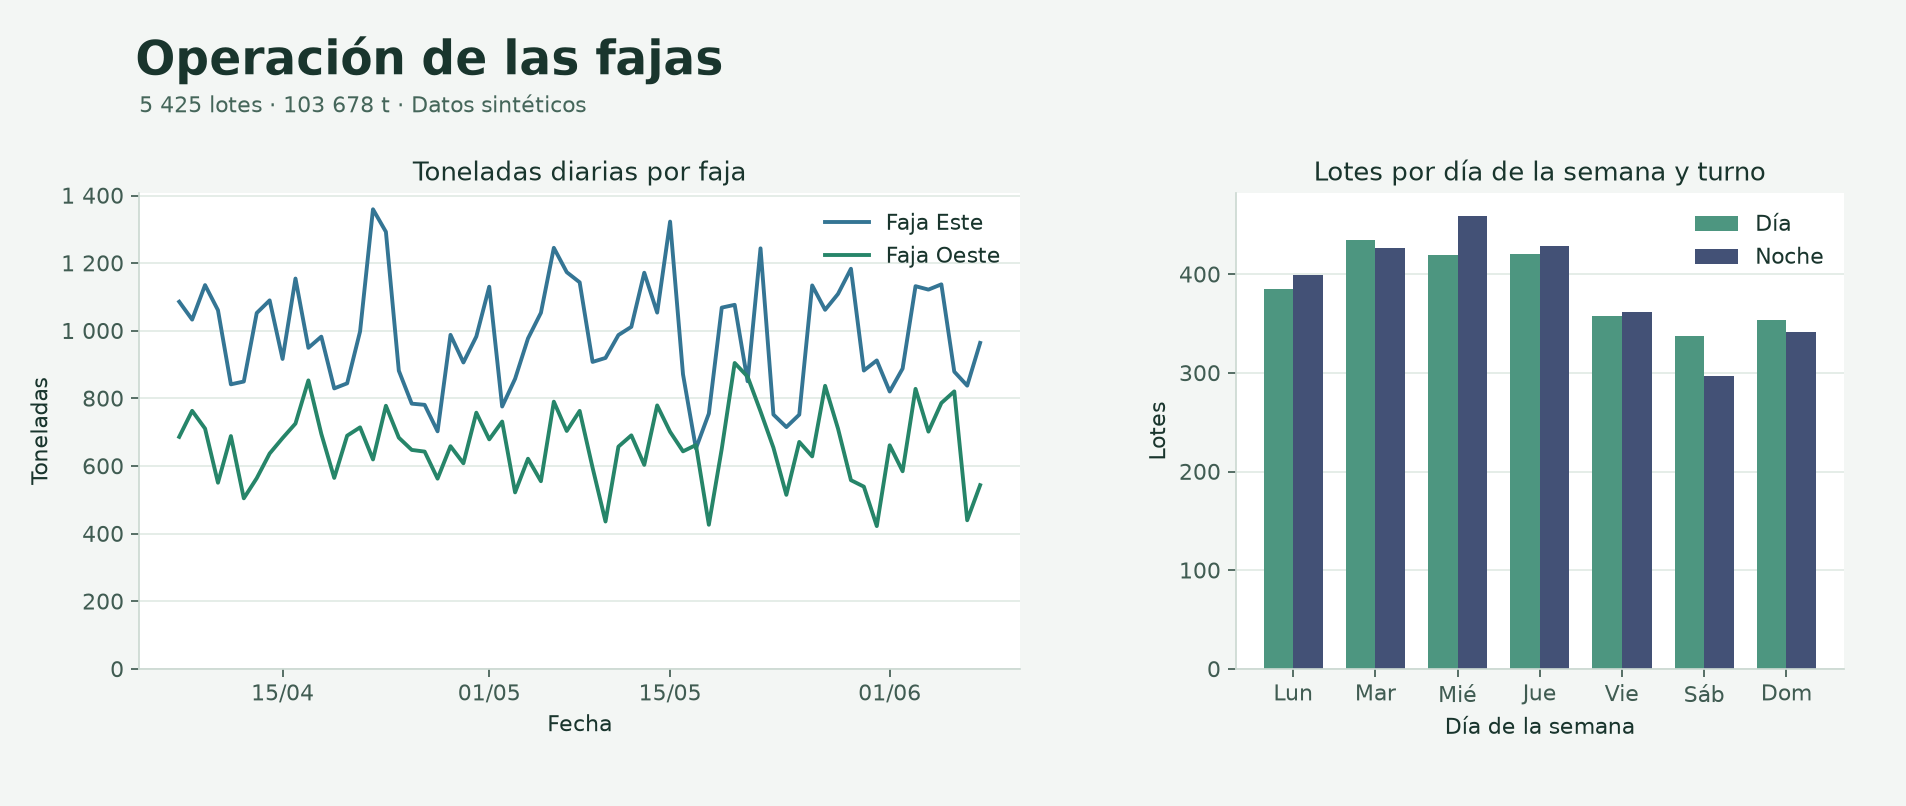

In [2]:
ruta = graficos / "01_operacion.png"
grafico_operacion(lotes, ruta)
display(Image(filename=str(ruta), width=1050))

## 3. Calibración y prueba cronológica

Para ajustar las calibraciones se usan únicamente los lotes e informes disponibles antes del **19 de mayo de 2025**. Los lotes medidos desde esa fecha forman la prueba.

- **Lectura directa.** Usa el valor del sensor.
- **Corrección de sesgo.** Resta el promedio de los errores observados durante el ajuste.
- **Regresión contextual.** Estima la ley de laboratorio por mínimos cuadrados con la lectura del sensor, la humedad centrada en 7 %, las horas desde la última verificación y un indicador de Faja Oeste.

El ensayo de laboratorio es la referencia por lote. Para cada método, el error es la ley estimada menos la ley de laboratorio. El sesgo es el promedio del error, el MAE promedia su magnitud absoluta y el RMSE da mayor peso a los errores grandes. Las tres métricas se expresan en puntos porcentuales.

In [3]:
corte = pd.Timestamp("2025-05-19")
prueba, metricas, coeficientes, n_ajuste, diferidos = evaluar(pares, corte)

print(f"Lotes usados para el ajuste: {n_ajuste}")
print(f"Lotes usados para la prueba: {len(prueba)}")
print(f"Informes previos aún pendientes al corte: {diferidos}")

Lotes usados para el ajuste: 940
Lotes usados para la prueba: 431
Informes previos aún pendientes al corte: 13


## 4. Concordancia con el laboratorio

Cada punto representa un lote de prueba. La distancia a la diagonal ayuda a ver dónde se concentra la sobreestimación o la subestimación.

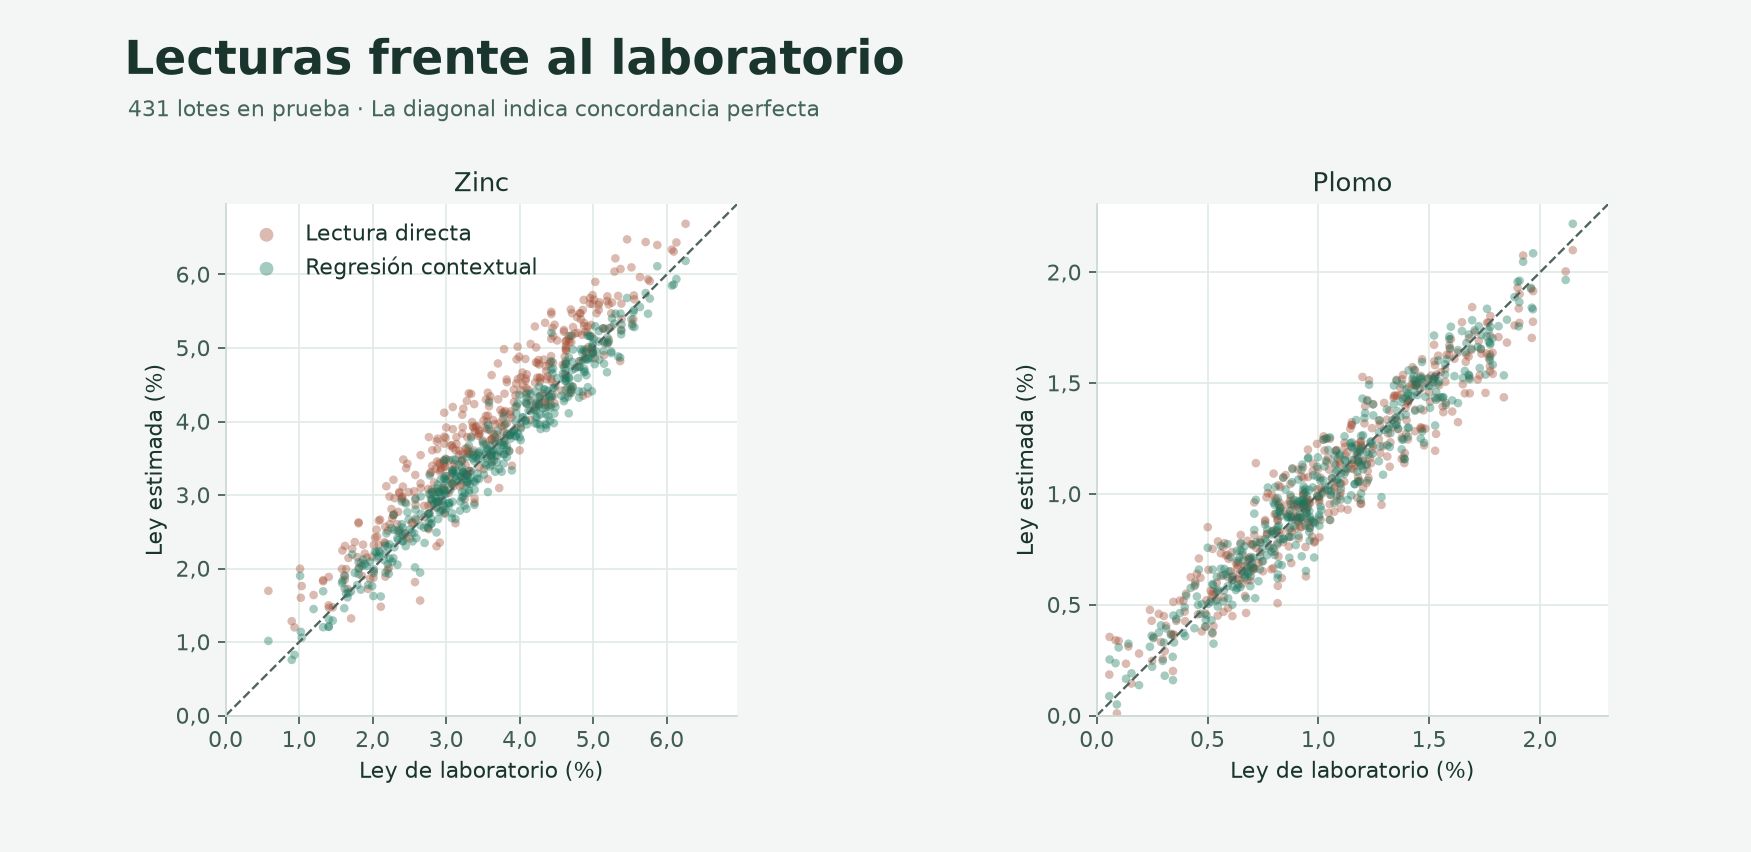

In [4]:
ruta = graficos / "02_concordancia.png"
grafico_concordancia(prueba, ruta)
display(Image(filename=str(ruta), width=1050))

## 5. Comparación de los métodos

El zinc presenta el mayor beneficio de la calibración contextual en esta simulación. En plomo, el sesgo de la lectura directa está cerca de cero y aun así la regresión reduce el error absoluto medio por lote.

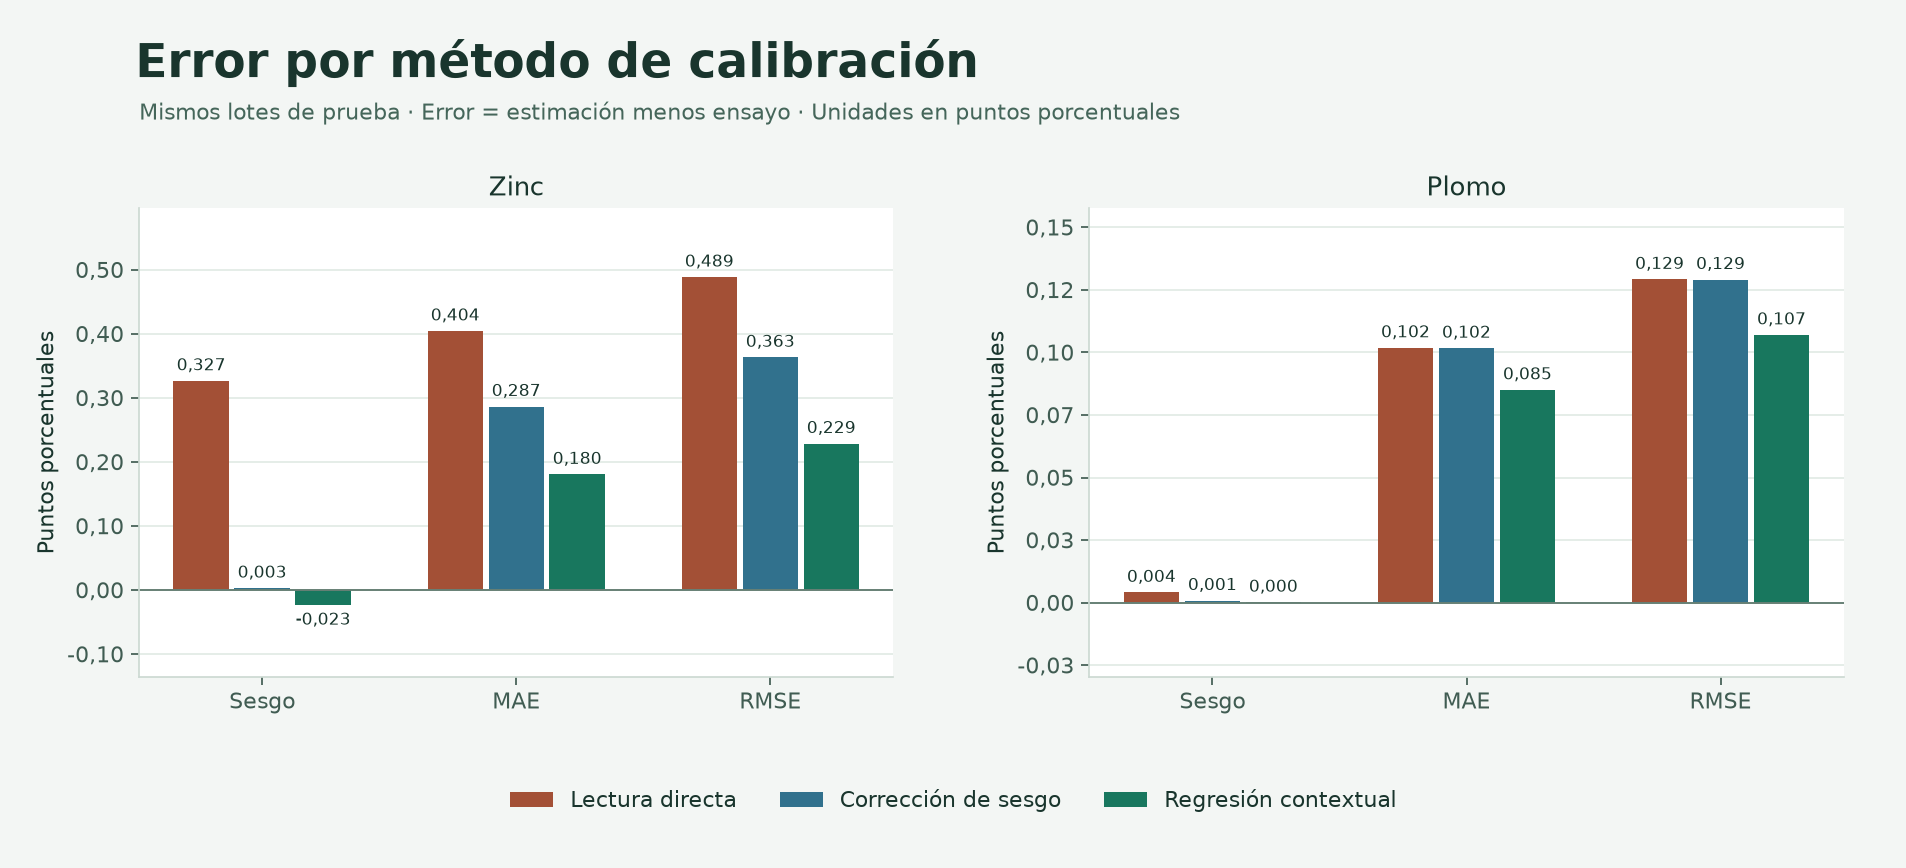

Sesgo (p. p.) MAE (p. p.) RMSE (p. p.)
metal metodo                                                     
Zinc  Lectura directa             0,3267      0,4044       0,4885
      Corrección de sesgo         0,0030      0,2865       0,3632
      Regresión contextual       -0,0234      0,1805       0,2287
Plomo Lectura directa             0,0041      0,1018       0,1292
      Corrección de sesgo         0,0008      0,1017       0,1291
      Regresión contextual        0,0002      0,0850       0,1070

In [5]:
ruta = graficos / "03_metricas.png"
grafico_metricas(metricas, ruta)
display(Image(filename=str(ruta), width=1050))

columnas_error = ["sesgo_pp", "mae_pp", "rmse_pp"]
tabla = metricas.set_index(["metal", "metodo"])[columnas_error]
display(tabla.rename(columns={
    "sesgo_pp": "Sesgo (p. p.)",
    "mae_pp": "MAE (p. p.)",
    "rmse_pp": "RMSE (p. p.)",
}).map(lambda valor: decimal(valor, 4)))

## 6. Diagnóstico por humedad

Los promedios por tramo muestran si el sesgo cambia con la humedad y cómo se comporta la corrección contextual. El tamaño de cada grupo aparece debajo del tramo.

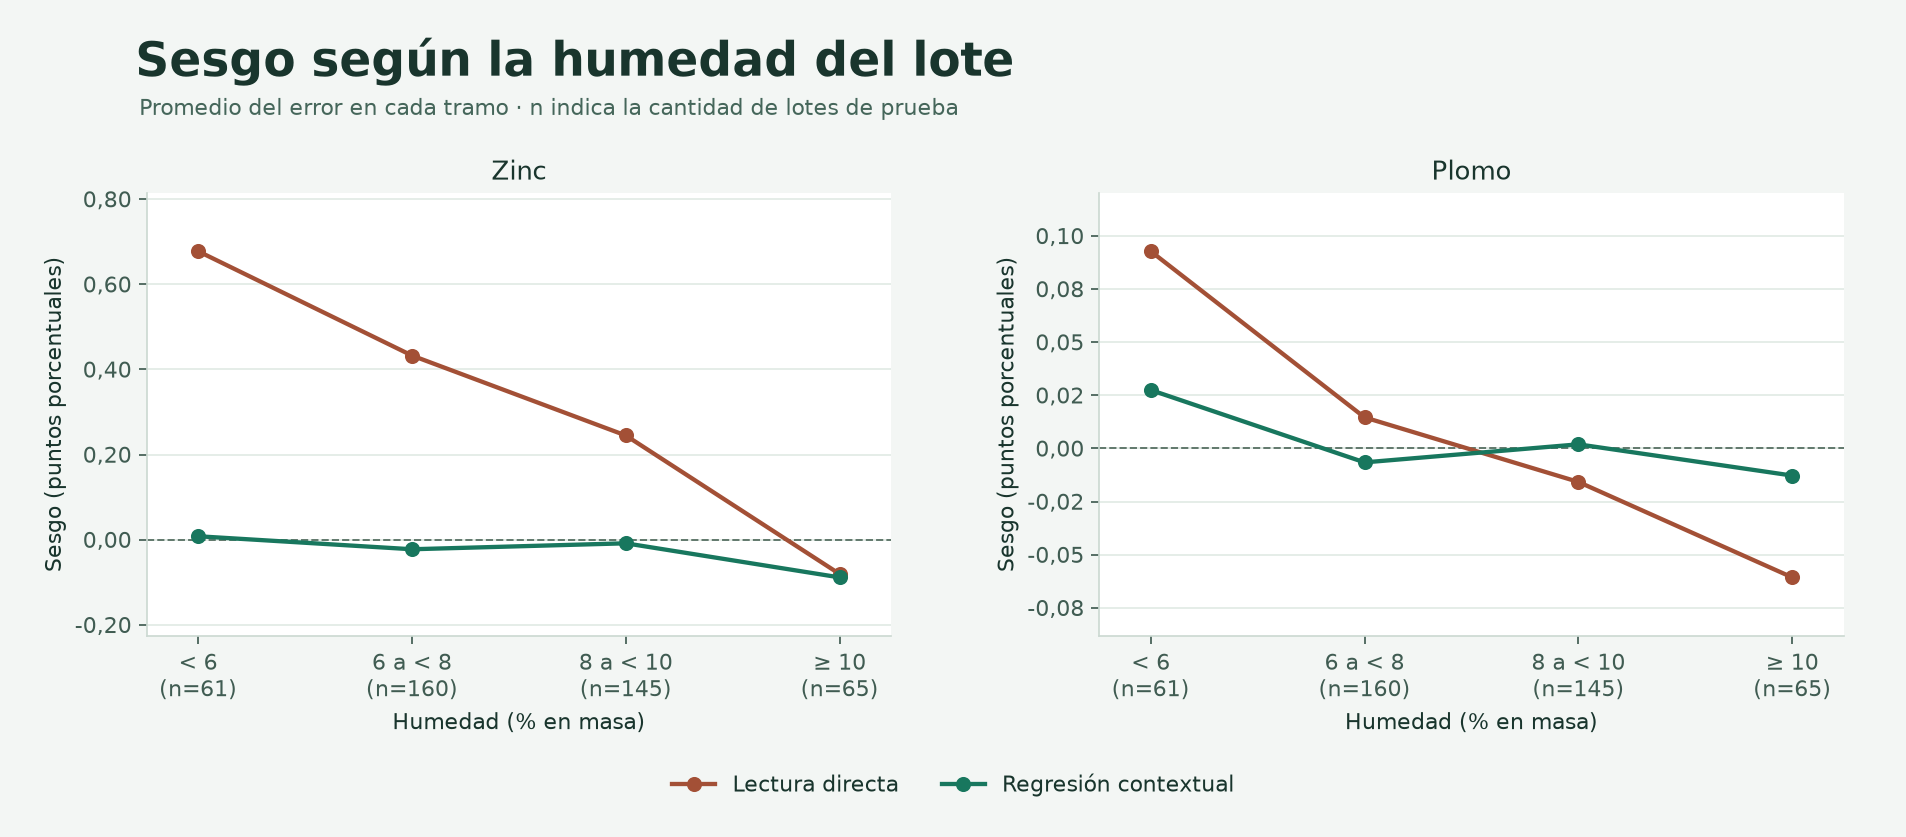

In [6]:
ruta = graficos / "04_humedad.png"
grafico_humedad(prueba, ruta)
display(Image(filename=str(ruta), width=1050))

## 7. Lotes dentro de una tolerancia

Para una tolerancia dada en puntos porcentuales, la altura de la curva muestra qué proporción de lotes quedó dentro de ese margen frente al laboratorio. El siguiente cálculo usa **0,20 puntos porcentuales** como ejemplo ilustrativo.

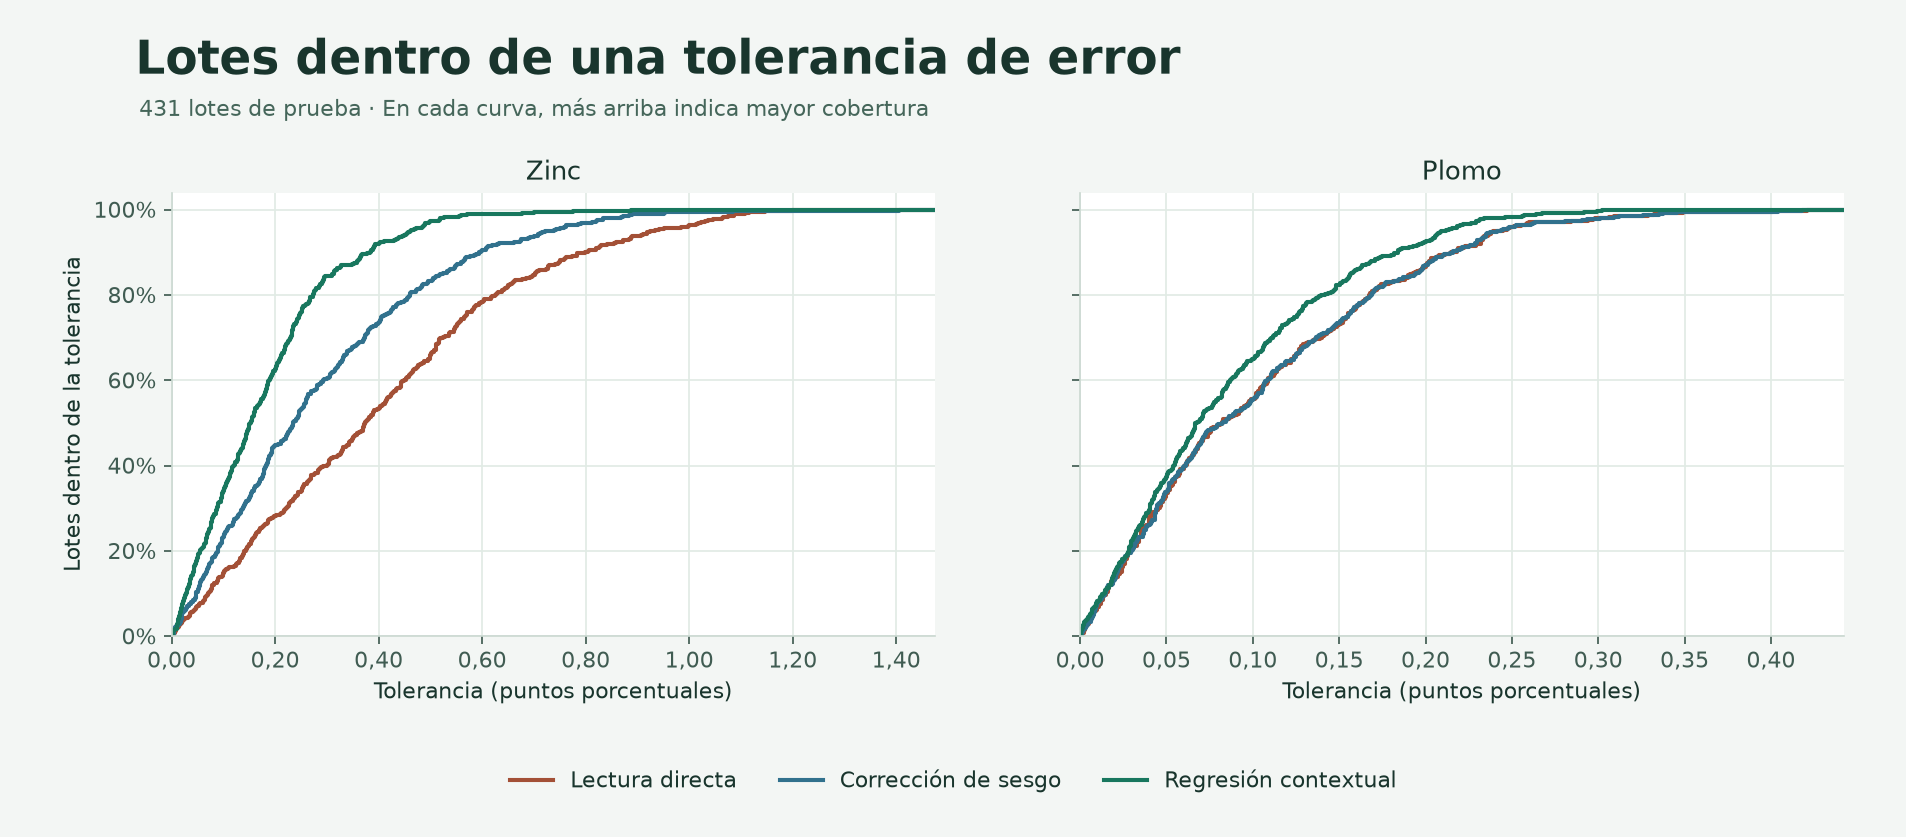

Zinc: 28,1 % con lectura directa y 62,2 % con regresión contextual.
Plomo: 87,0 % con lectura directa y 92,3 % con regresión contextual.


In [7]:
ruta = graficos / "05_tolerancia.png"
grafico_tolerancia(prueba, ruta)
display(Image(filename=str(ruta), width=1050))

tolerancia_pp = 0.20
for metal, nombre in {"zn": "Zinc", "pb": "Plomo"}.items():
    directa = prueba[f"{metal}_directo_error_pp"].abs().le(tolerancia_pp).mean()
    contextual = prueba[f"{metal}_contexto_error_pp"].abs().le(tolerancia_pp).mean()
    print(f"{nombre}: {decimal(directa * 100, 1)} % con lectura directa y "
          f"{decimal(contextual * 100, 1)} % con regresión contextual.")

Los resultados describen un escenario simulado. Tanto la variación de las leyes como los efectos de humedad, deriva y ruido forman parte de los supuestos del caso.